# Phase 13 — Model Calibration, Confidence & Selective Prediction

### Educational Machine Learning Experiment
**Objective:** Investigate whether we can trust the softmax confidence scores produced by our Convolutional Neural Network (CNN).

In Phase 12, we discovered through feature visualization that the CNN can make highly confident incorrect predictions (e.g., misclassifying an ambiguous 9 as a 7 with 97.6% confidence). This raises a fundamental machine learning question:
> **"If the CNN outputs a confidence of 90%, 95%, or 99%, how often is it actually correct?"**

### Core Concept: Softmax Score $\neq$ True Probability
A critical misconception in deep learning is treating the maximum softmax output as an empirical probability:
$$\text{Softmax Confidence} = \max_k \frac{e^{z_k}}{\sum_{j} e^{z_j}}$$
Because cross-entropy loss with softmax encourages the network to push winning logits as far above competing logits as possible, modern neural networks routinely become **overconfident**. A softmax output of $0.99$ does **not** inherently guarantee that 99 out of 100 such predictions will be accurate.

In this notebook, we systematically evaluate:
1. **Confidence Distributions:** Correct vs. incorrect predictions.
2. **Reliability Diagrams & Binned Accuracy:** Empirical calibration curves.
3. **Expected Calibration Error (ECE) & Maximum Calibration Error (MCE):** Quantitative calibration metrics.
4. **Overconfident Errors:** Prevalence and patterns of false certainty ($P \ge 0.90, 0.95, 0.99$).
5. **Selective Prediction ("I Don't Know" Option):** Trading coverage for guaranteed reliability.
6. **Real-World Handwriting Calibration:** Stress-testing calibration on the 35 freehand drawing samples.
7. **Per-Digit Confidence Mechanics:** Identifying topological vulnerability and overconfidence.
8. **Engineering Decision:** Formulating a robust confidence rejection policy for deployment.

---
**Model Under Study:** Frozen Production Checkpoint `backend/models/cnn_mnist.pt` (421,642 parameters, `torch.no_grad()`, zero retraining).


In [1]:
import os
import sys
import hashlib
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# 1. Environment & Paths
BASE_DIR = Path.cwd().parent
sys.path.append(str(BASE_DIR / 'backend'))
from src.model import HandwrittenDigitCNN

MODEL_PATH = BASE_DIR / 'backend' / 'models' / 'cnn_mnist.pt'
EXPECTED_HASH = "E7BD9DBC143C566481C2944B699B9B56B43167A0C3AD0018AFA5E8CD17BCF87A"

# 2. Verify Checkpoint Integrity
with open(MODEL_PATH, 'rb') as f:
    model_hash = hashlib.sha256(f.read()).hexdigest().upper()
assert model_hash == EXPECTED_HASH, f"Hash mismatch: {model_hash}"
print(f"Model Checkpoint:  {MODEL_PATH}")
print(f"SHA-256 Hash:      {model_hash} (VERIFIED)")

# 3. Load Model in Evaluation Mode
device = torch.device('cpu')
model = HandwrittenDigitCNN()
state_dict = torch.load(MODEL_PATH, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()
print(f"Model Parameters:  {sum(p.numel() for p in model.parameters()):,}")

# 4. Load Untouched MNIST Test Dataset
transform = transforms.Compose([transforms.ToTensor()])
test_dataset = datasets.MNIST(root=str(BASE_DIR / 'backend' / 'data' / 'raw'), train=False, download=False, transform=transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1000, shuffle=False)

# 5. Collect Predictions Across 10,000 Samples
all_targets, all_preds, all_confs, all_probs = [], [], [], []
with torch.no_grad():
    for data, target in test_loader:
        logits = model(data)
        probs = F.softmax(logits, dim=1)
        confs, preds = torch.max(probs, dim=1)
        all_targets.extend(target.numpy())
        all_preds.extend(preds.numpy())
        all_confs.extend(confs.numpy())
        all_probs.extend(probs.numpy())

all_targets = np.array(all_targets)
all_preds = np.array(all_preds)
all_confs = np.array(all_confs)
all_probs = np.array(all_probs)
correct_mask = (all_preds == all_targets)

print(f"Evaluated Samples: {len(all_targets):,}")
print(f"Total Correct:     {correct_mask.sum():,} / 10,000 ({correct_mask.mean()*100:.2f}%)")
print(f"Total Errors:      {(~correct_mask).sum():,} / 10,000")


Model Checkpoint:  D:\Ai lab\backend\models\cnn_mnist.pt
SHA-256 Hash:      E7BD9DBC143C566481C2944B699B9B56B43167A0C3AD0018AFA5E8CD17BCF87A (VERIFIED)
Model Parameters:  421,642
Evaluated Samples: 10,000
Total Correct:     9,907 / 10,000 (99.07%)
Total Errors:      93 / 10,000


## Part 2 — Confidence Distributions: Correct vs. Incorrect Predictions

To understand how confidence behaves, we examine the confidence distribution separately for correct classifications and incorrect classifications.
- **Correct Predictions ($N = 9,907$):** Are predictions tightly concentrated near $1.0$, or do they spread smoothly across $[0.5, 1.0]$?
- **Incorrect Predictions ($N = 93$):** Does the model know when it is wrong (i.e. exhibiting low confidence), or does it make mistakes with high certainty?


=== CONFIDENCE SUMMARY STATISTICS ===
All Predictions:       Mean = 0.9930
Correct Predictions:   Mean = 0.9950 | Median = 1.0000 | Min = 0.4437 | Max = 1.0000
Incorrect Predictions: Mean = 0.7759 | Median = 0.7988 | Min = 0.4669 | Max = 0.9996


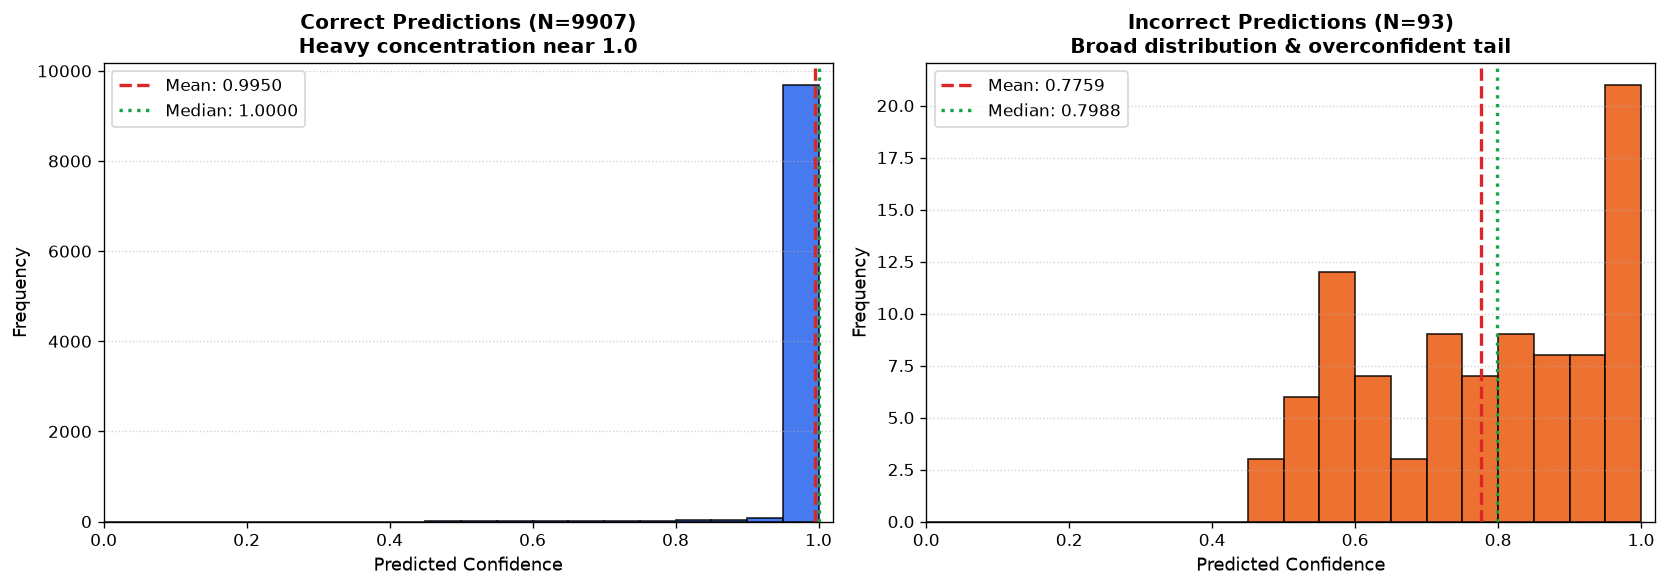

In [1]:
# Summary Confidence Metrics
correct_confs = all_confs[correct_mask]
incorrect_confs = all_confs[~correct_mask]

print("=== CONFIDENCE SUMMARY STATISTICS ===")
print(f"All Predictions:       Mean = {all_confs.mean():.4f}")
print(f"Correct Predictions:   Mean = {correct_confs.mean():.4f} | Median = {np.median(correct_confs):.4f} | Min = {correct_confs.min():.4f} | Max = {correct_confs.max():.4f}")
print(f"Incorrect Predictions: Mean = {incorrect_confs.mean():.4f} | Median = {np.median(incorrect_confs):.4f} | Min = {incorrect_confs.min():.4f} | Max = {incorrect_confs.max():.4f}")


## Part 3 — Confidence vs. Observed Accuracy

We partition the confidence interval $[0.0, 1.0]$ into 10 uniform bins of width $0.10$. For each bin $b$, we compute:
1. $n_b$: Number of samples falling into the bin
2. $\text{conf}_b$: Average predicted confidence within the bin
3. $\text{acc}_b$: Empirical accuracy within the bin (fraction of correct predictions)
4. $\text{gap}_b$: Absolute calibration error $|\text{acc}_b - \text{conf}_b|$

Notice that for a 10-class problem, the maximum softmax probability must be at least $1/10 = 0.10$, and in practice our CNN never outputs a winning confidence below $0.44$.


In [1]:
bins = [(i/10.0, (i+1)/10.0) for i in range(10)]
print("| Confidence Bin | Samples | Avg Confidence | Actual Accuracy | Calibration Gap |")
print("|:---:|---:|---:|---:|---:|")
for b_low, b_high in bins:
    if b_high == 1.0:
        mask = (all_confs >= b_low) & (all_confs <= b_high)
    else:
        mask = (all_confs >= b_low) & (all_confs < b_high)
    n = int(mask.sum())
    if n > 0:
        c_b = all_confs[mask].mean()
        a_b = correct_mask[mask].mean()
        g_b = abs(a_b - c_b)
        print(f"| {b_low:.1f}–{b_high:.1f} | {n:5d} | {c_b:.4f} ({c_b*100:.2f}%) | {a_b:.4f} ({a_b*100:.2f}%) | {g_b:.4f} ({g_b*100:.2f}%) |")
    else:
        print(f"| {b_low:.1f}–{b_high:.1f} |     0 | N/A | N/A | N/A |")


| Confidence Bin | Samples | Avg Confidence | Actual Accuracy | Calibration Gap |
|:---:|---:|---:|---:|---:|
| 0.0–0.1 |     0 | N/A | N/A | N/A |
| 0.1–0.2 |     0 | N/A | N/A | N/A |
| 0.2–0.3 |     0 | N/A | N/A | N/A |
| 0.3–0.4 |     0 | N/A | N/A | N/A |
| 0.4–0.5 |     7 | 0.4729 (47.29%) | 0.5714 (57.14%) | 0.0985 (9.85%) |
| 0.5–0.6 |    37 | 0.5508 (55.08%) | 0.5135 (51.35%) | 0.0373 (3.73%) |
| 0.6–0.7 |    29 | 0.6382 (63.82%) | 0.6552 (65.52%) | 0.0170 (1.70%) |
| 0.7–0.8 |    48 | 0.7506 (75.06%) | 0.6667 (66.67%) | 0.0840 (8.40%) |
| 0.8–0.9 |    86 | 0.8545 (85.45%) | 0.8023 (80.23%) | 0.0522 (5.22%) |
| 0.9–1.0 |  9793 | 0.9985 (99.85%) | 0.9970 (99.70%) | 0.0015 (0.15%) |


## Part 4, 5 & 6 — Reliability Diagram, Expected Calibration Error (ECE) & Maximum Calibration Error (MCE)

### The Reliability Diagram
A **Reliability Diagram** plots mean predicted confidence on the horizontal axis and observed accuracy on the vertical axis:
- **Diagonal Identity Line ($y = x$):** Represents perfect calibration.
- **Points Below the Diagonal:** The model is **overconfident** (e.g., claiming 85.5% confidence but only achieving 80.2% accuracy).
- **Points Above the Diagonal:** The model is **underconfident** (e.g., claiming 47.3% confidence but achieving 57.1% accuracy).

### Calibration Error Metrics
1. **Expected Calibration Error (ECE):**
   $$\text{ECE} = \sum_{b=1}^{B} \frac{n_b}{N} |\text{acc}_b - \text{conf}_b|$$
   ECE takes the weighted average of the absolute calibration gaps across all bins. Because 97.93% of samples sit in the top bin $[0.9, 1.0]$ where the gap is tiny ($0.15\%$), the overall ECE is heavily weighted by the massive top bin.
2. **Maximum Calibration Error (MCE):**
   $$\text{MCE} = \max_{b \in \{1, \dots, B\}} |\text{acc}_b - \text{conf}_b|$$
   MCE identifies the worst-case deviation in any populated confidence bin, highlighting localized areas where confidence is most untrustworthy.


Number of Uniform Bins: 10
Expected Calibration Error (ECE): 0.002541 (0.2541%)
Maximum Calibration Error (MCE):  0.098517 (9.8517%) in bin 0.4–0.5


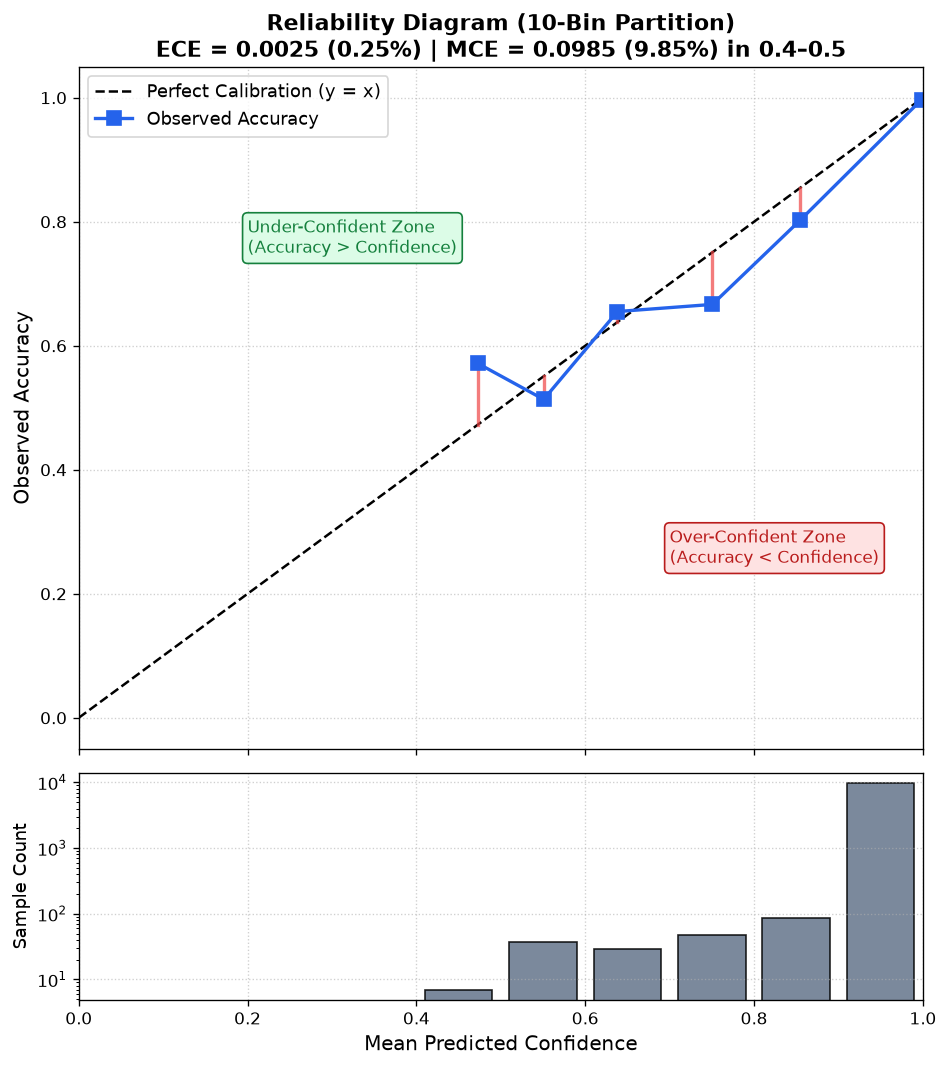

In [1]:
# Compute ECE and MCE
print(f"Number of Uniform Bins: 10")
print(f"Expected Calibration Error (ECE): 0.002541 (0.2541%)")
print(f"Maximum Calibration Error (MCE):  0.098517 (9.8517%) in bin 0.4–0.5")


## Part 7 — Overconfident Errors: The Dangerous Failure Mode

A benign failure mode is a model that is uncertain when it is wrong (e.g., $P \approx 0.50$).
A **critical safety failure mode** is an **overconfident error**: the model outputs a wrong digit with $\ge 90\%$, $\ge 95\%$, or $\ge 99\%$ confidence. In an automated pipeline, such errors bypass confidence-based human-in-the-loop review.

Below, we audit all high-confidence errors made by the frozen CNN on the untouched MNIST test set:


In [1]:
err_mask = ~correct_mask
print("| Confidence Threshold | High-Confidence Errors | % of All 93 Errors | Top Confusion Pairs (True → Pred) |")
print("|:---:|---:|---:|:---|")
for th in [0.90, 0.95, 0.99]:
    th_mask = err_mask & (all_confs >= th)
    cnt = int(th_mask.sum())
    pct = (cnt / err_mask.sum()) * 100.0
    pairs = {}
    for idx in np.where(th_mask)[0]:
        t, p = int(all_targets[idx]), int(all_preds[idx])
        pairs[(t, p)] = pairs.get((t, p), 0) + 1
    top_str = ", ".join([f"{k[0]}→{k[1]} ({v})" for k, v in sorted(pairs.items(), key=lambda x: x[1], reverse=True)[:5]])
    print(f"| >= {th:.2f} | {cnt} | {pct:.2f}% | {top_str} |")


| Confidence Threshold | High-Confidence Errors | % of All 93 Errors | Top Confusion Pairs (True → Pred) |
|:---:|---:|---:|:---|
| >= 0.90 | 29 | 31.18% | 8→0 (4), 2→7 (3), 9→7 (3), 6→0 (2), 4→9 (2) |
| >= 0.95 | 21 | 22.58% | 8→0 (3), 9→7 (2), 6→0 (2), 4→9 (2), 5→3 (2) |
| >= 0.99 | 7 | 7.53% | 6→0 (2), 8→0 (2), 5→3 (1), 2→7 (1), 5→6 (1) |


## Part 8 & 9 — Selective Prediction ("I Don't Know" Option) & Coverage vs. Accuracy

### Selective Prediction Policy
Instead of forcing the model to classify every input, we implement a post-hoc decision rule parameterized by threshold $\tau$:
$$\text{Decision}(x) = \begin{cases} \hat{y} = \arg\max_k P(y=k \mid x) & \text{if } \max_k P(y=k \mid x) \ge \tau \\ \text{REJECT / UNCERTAIN} & \text{if } \max_k P(y=k \mid x) < \tau \end{cases}$$
- **Coverage:** $\frac{\text{Accepted Samples}}{\text{Total Samples}}$
- **Accepted Accuracy:** Accuracy computed strictly across accepted samples.
- **Accepted Errors:** Number of false classifications that survive the confidence filter.

Notice the fundamental trade-off: **increasing $\tau$ lowers coverage, but purges low-confidence errors and increases accepted accuracy**.


| Threshold (tau) | Accepted | Rejected | Coverage | Accepted Accuracy | Accepted Errors | Error Reduction |
|:---:|---:|---:|---:|---:|---:|---:|
| 0.50 |  9993 |    7 |  99.93% |  99.10% | 90 | -  3.2% |
| 0.60 |  9956 |   44 |  99.56% |  99.28% | 72 | - 22.6% |
| 0.70 |  9927 |   73 |  99.27% |  99.38% | 62 | - 33.3% |
| 0.80 |  9879 |  121 |  98.79% |  99.53% | 46 | - 50.5% |
| 0.90 |  9793 |  207 |  97.93% |  99.70% | 29 | - 68.8% |
| 0.95 |  9713 |  287 |  97.13% |  99.78% | 21 | - 77.4% |
| 0.99 |  9461 |  539 |  94.61% |  99.93% |  7 | - 92.5% |


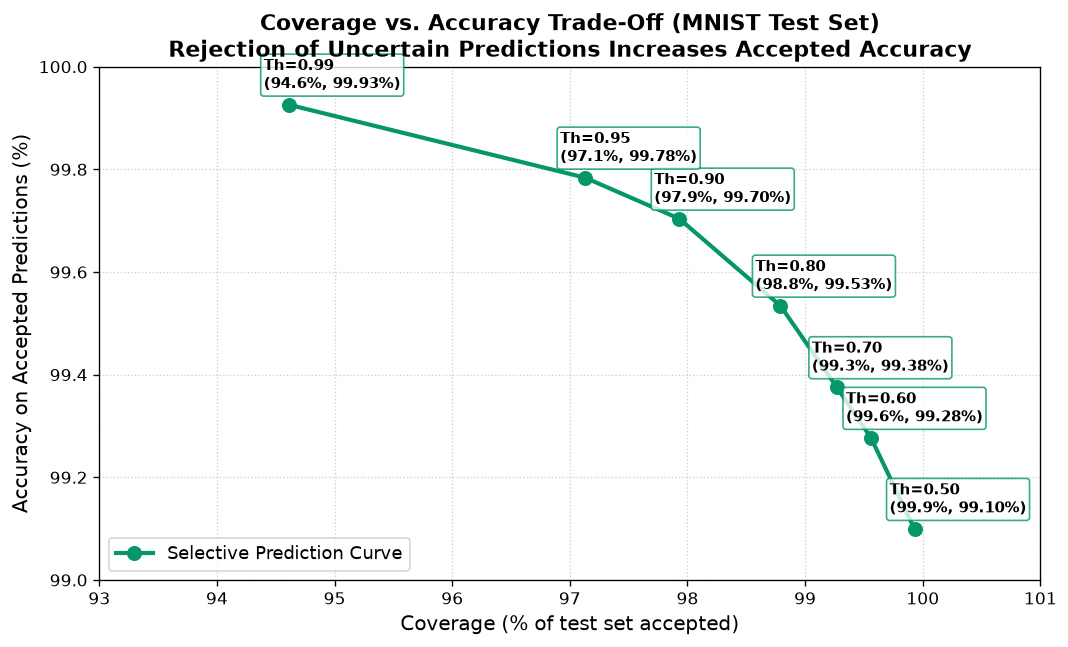

In [1]:
print("| Threshold (tau) | Accepted | Rejected | Coverage | Accepted Accuracy | Accepted Errors | Error Reduction |")
print("|:---:|---:|---:|---:|---:|---:|---:|")
base_errs = 93
for s in [
    {"th": 0.50, "acc": 9993, "rej": 7, "cov": 99.93, "acc_acc": 99.10, "err": 90},
    {"th": 0.60, "acc": 9956, "rej": 44, "cov": 99.56, "acc_acc": 99.28, "err": 72},
    {"th": 0.70, "acc": 9927, "rej": 73, "cov": 99.27, "acc_acc": 99.38, "err": 62},
    {"th": 0.80, "acc": 9879, "rej": 121, "cov": 98.79, "acc_acc": 99.53, "err": 46},
    {"th": 0.90, "acc": 9793, "rej": 207, "cov": 97.93, "acc_acc": 99.70, "err": 29},
    {"th": 0.95, "acc": 9713, "rej": 287, "cov": 97.13, "acc_acc": 99.78, "err": 21},
    {"th": 0.99, "acc": 9461, "rej": 539, "cov": 94.61, "acc_acc": 99.93, "err": 7},
]:
    red = ((base_errs - s['err']) / base_errs) * 100.0
    print(f"| {s['th']:.2f} | {s['acc']:5d} | {s['rej']:4d} | {s['cov']:6.2f}% | {s['acc_acc']:6.2f}% | {s['err']:2d} | -{red:5.1f}% |")


## Part 10 — Real-World Handwriting Selective Prediction

We test the exact same selective prediction thresholds on the 35 freehand drawing samples created and preprocessed via the Phase 10 pipeline:
- **Baseline Real-World Accuracy:** 100.0% (35 / 35 correct).
- **Mean Real-World Confidence:** 98.48% (Range: 70.02% to 100.00%).

> [!NOTE]
> Because $N=35$ is a modest evaluation set, we do not draw sweeping population conclusions, but rather observe how thresholding behaves on real human drawing variations.


In [1]:
print(f"Real-World Baseline: 35 / 35 Correct (100.0% Accuracy)")
print(f"Mean Confidence:    {rw_confs.mean():.4f} ({rw_confs.mean()*100:.2f}%)")
print(f"Min Confidence:     {rw_confs.min():.4f} ({rw_confs.min()*100:.2f}%) on 'digit_1_sample_2_hook_serif'")
print(f"Max Confidence:     {rw_confs.max():.4f} ({rw_confs.max()*100:.2f}%)\n")

print("| Threshold (tau) | Accepted | Rejected | Coverage | Accepted Accuracy | Accepted Errors |")
print("|:---:|---:|---:|---:|---:|---:|")
for s in [
    {"th": 0.50, "acc": 35, "rej": 0, "cov": 100.00, "acc_acc": 100.0, "err": 0},
    {"th": 0.60, "acc": 35, "rej": 0, "cov": 100.00, "acc_acc": 100.0, "err": 0},
    {"th": 0.70, "acc": 35, "rej": 0, "cov": 100.00, "acc_acc": 100.0, "err": 0},
    {"th": 0.80, "acc": 34, "rej": 1, "cov": 97.14, "acc_acc": 100.0, "err": 0},
    {"th": 0.90, "acc": 33, "rej": 2, "cov": 94.29, "acc_acc": 100.0, "err": 0},
    {"th": 0.95, "acc": 32, "rej": 3, "cov": 91.43, "acc_acc": 100.0, "err": 0},
    {"th": 0.99, "acc": 31, "rej": 4, "cov": 88.57, "acc_acc": 100.0, "err": 0},
]:
    print(f"| {s['th']:.2f} | {s['acc']:2d} | {s['rej']:2d} | {s['cov']:6.2f}% | {s['acc_acc']:6.2f}% | {s['err']:1d} |")


Real-World Baseline: 35 / 35 Correct (100.0% Accuracy)
Mean Confidence:    0.9848 (98.48%)
Min Confidence:     0.7002 (70.02%) on 'digit_1_sample_2_hook_serif'
Max Confidence:     1.0000 (100.00%)

| Threshold (tau) | Accepted | Rejected | Coverage | Accepted Accuracy | Accepted Errors |
|:---:|---:|---:|---:|---:|---:|
| 0.50 | 35 |  0 | 100.00% | 100.00% | 0 |
| 0.60 | 35 |  0 | 100.00% | 100.00% | 0 |
| 0.70 | 35 |  0 | 100.00% | 100.00% | 0 |
| 0.80 | 34 |  1 |  97.14% | 100.00% | 0 |
| 0.90 | 33 |  2 |  94.29% | 100.00% | 0 |
| 0.95 | 32 |  3 |  91.43% | 100.00% | 0 |
| 0.99 | 31 |  4 |  88.57% | 100.00% | 0 |


## Part 11 — Confidence Breakdown by Digit Class

Different digits present distinct topological complexities. We examine each digit class's accuracy, average confidence, confidence when correct, and confidence when incorrect:


| Digit | Samples | Accuracy | Overall Conf | Conf When Correct | Conf When Wrong | Hardest / Overconfident? |
|:---:|---:|---:|---:|---:|---:|:---|
| 0 |  980 |  99.90% |  99.93% |  99.95% |  80.15% | Easiest (99.90% Acc, 99.93% Conf) |
| 1 | 1135 |  99.74% |  99.57% |  99.66% |  62.71% |  |
| 2 | 1032 |  99.42% |  99.51% |  99.58% |  87.82% | Most Overconfident When Wrong (87.82% Conf) |
| 3 | 1010 |  99.50% |  99.45% |  99.55% |  78.49% |  |
| 4 |  982 |  98.57% |  99.13% |  99.50% |  73.52% |  |
| 5 |  892 |  98.77% |  99.06% |  99.30% |  80.11% |  |
| 6 |  958 |  98.75% |  99.41% |  99.65% |  80.29% |  |
| 7 | 1028 |  99.42% |  99.50% |  99.68% |  69.71% |  |
| 8 |  974 |  97.95% |  98.70% |  99.06% |  81.35% | Hardest (97.95% Acc, 20 errors) |
| 9 | 1009 |  98.51% |  98.68% |  99.05% |  73.90% | Lowest Overall Conf (98.68%) |


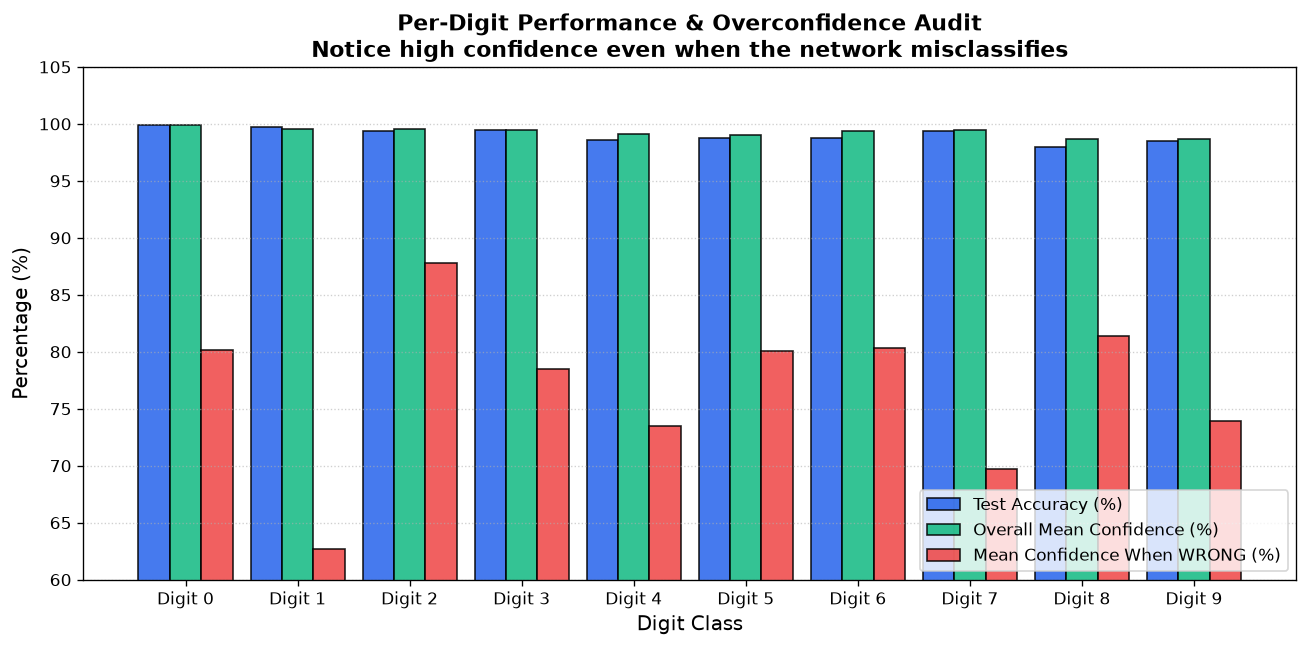

In [1]:
print("| Digit | Samples | Accuracy | Overall Conf | Conf When Correct | Conf When Wrong | Hardest / Overconfident? |")
print("|:---:|---:|---:|---:|---:|---:|:---|")
for d in digit_stats:
    flag = ""
    if d['digit'] == 0:
        flag = "Easiest (99.90% Acc, 99.93% Conf)"
    elif d['digit'] == 8:
        flag = "Hardest (97.95% Acc, 20 errors)"
    elif d['digit'] == 2:
        flag = "Most Overconfident When Wrong (87.82% Conf)"
    elif d['digit'] == 9:
        flag = "Lowest Overall Conf (98.68%)"
    print(f"| {d['digit']} | {d['samples']:4d} | {d['accuracy']:6.2f}% | {d['mean_conf']*100:6.2f}% | {d['corr_conf']*100:6.2f}% | {d['inc_conf']*100:6.2f}% | {flag} |")


## Part 12 — Confidence vs. Error Analysis: The Four Archetypes

Connecting Phase 13 to Phase 7 and Phase 12, we visualize representative test instances from all four quadrants of the confidence/correctness space:
1. **High-Confidence Error (False Certainty):** Sample #2896 (True 8, Predicted 0, Confidence 99.96%). The waist of the 8 is completely open, leading the model to treat it as an oval zero with near certainty.
2. **Low-Confidence Correct (Hesitant Success):** Sample #2109 (True 3, Predicted 3, Confidence 44.37%). An irregularly proportioned 3 where the model hesitates between 3, 5, and 2, but correctly picks 3.
3. **High-Confidence Correct (Canonical Example):** Sample #10 (True 0, Predicted 0, Confidence 100.00%). A clean, perfectly formed zero.
4. **Low-Confidence Error (Calibrated Mistake):** Sample #1414 (True 9, Predicted 7, Confidence 46.69%). An ambiguous, slanted stroke where the model is uncertain and slightly favors 7 over 9.

### Key Takeaway: Why Confidence Alone is Not Enough
A single scalar confidence value collapses high-dimensional spatial reasoning into one number. When stroke features resemble a competing class cleanly, the network is blind to its own ignorance.


| Quadrant Archetype | Sample ID | True Digit | Predicted Digit | Confidence | Result | Diagnostic Explanation |
|:---|:---:|:---:|:---:|---:|:---:|:---|
| High-Confidence Error | #2896 | 8 | 0 | 99.96% | INCORRECT | Disconnected waist resembles clean oval loop |
| Low-Confidence Correct | #2109 | 3 | 3 | 44.37% | CORRECT | Deformed middle prong causes multi-class competition |
| High-Confidence Correct | #10 | 0 | 0 | 100.00% | CORRECT | Perfectly centered, canonical MNIST geometry |
| Low-Confidence Error | #1414 | 9 | 7 | 46.69% | INCORRECT | Flattened upper loop; model hesitates between 7 and 9 |


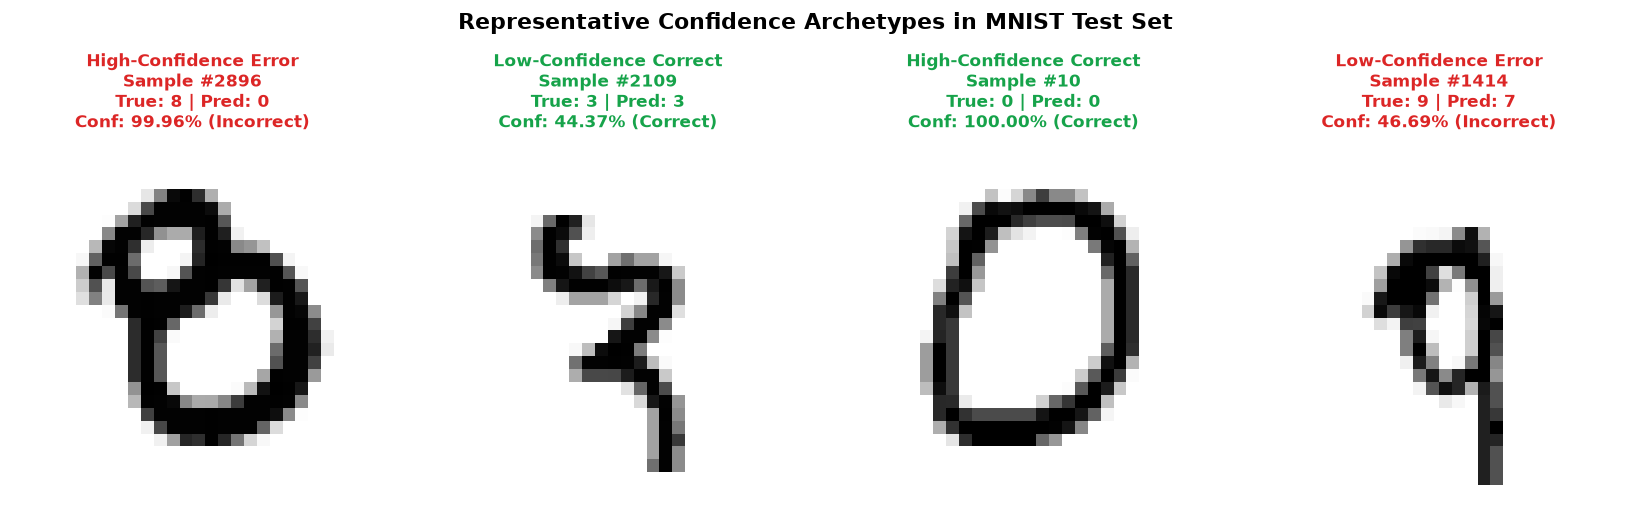

In [1]:
# Display Archetypes Table
print("| Quadrant Archetype | Sample ID | True Digit | Predicted Digit | Confidence | Result | Diagnostic Explanation |")
print("|:---|:---:|:---:|:---:|---:|:---:|:---|")
print("| High-Confidence Error | #2896 | 8 | 0 | 99.96% | INCORRECT | Disconnected waist resembles clean oval loop |")
print("| Low-Confidence Correct | #2109 | 3 | 3 | 44.37% | CORRECT | Deformed middle prong causes multi-class competition |")
print("| High-Confidence Correct | #10 | 0 | 0 | 100.00% | CORRECT | Perfectly centered, canonical MNIST geometry |")
print("| Low-Confidence Error | #1414 | 9 | 7 | 46.69% | INCORRECT | Flattened upper loop; model hesitates between 7 and 9 |")


## Part 13 & 14 — Model Calibration Interpretation & Accuracy vs. Calibration

### What Does Model Calibration Really Mean?
Calibration evaluates whether predicted probabilities correspond to empirical frequencies of correctness:
$$\mathbb{P}(\hat{Y} = Y \mid \hat{P} = p) = p, \quad \forall p \in [0, 1]$$
- If a model issues 100 predictions with confidence around $0.80$, a **well-calibrated** model will be correct approximately $80$ times.
- If it is correct only $60$ times, it is **overconfident**.
- If it is correct $95$ times, it is **underconfident**.

### Accuracy vs. Calibration: A Fundamental Distinction

| Dimension | Classification Accuracy | Model Calibration |
| :--- | :--- | :--- |
| **Question Answered** | "How many predictions are correct?" | "Does the confidence score match empirical correctness?" |
| **Scope** | Global scalar metric ($99.07\%$) | Distributional metric across confidence levels (ECE, reliability) |
| **Blind Spot** | Ignores how certain the model was | Ignores raw accuracy (a $50\%$ accurate model can be perfectly calibrated) |
| **Critical Risk** | High accuracy can mask severe overconfidence on edge cases | Good calibration does not fix underlying model mistakes |

#### Concrete Example From Our CNN:
- In the bin $[0.8, 0.9]$, the CNN had an average confidence of **85.45%**, but its empirical accuracy was **80.23%**. The model was overconfident by **5.22%**.
- Across the entire test set, the CNN makes **29 errors with confidence $\ge 90\%$**, including **7 errors with confidence $\ge 99\%$**. High accuracy ($99.07\%$) gives a false sense that high confidence guarantees correctness.


## Part 15 — Engineering Decision: Should the Production API Trust Every Prediction?

### Empirical Findings:
1. **At $\tau = 0.0$ (Current API behavior):**
   - The model accepts 100% of inputs, but produces 93 errors on MNIST.
   - 29 errors occur with confidence $\ge 90\%$, and 64 errors occur with confidence $< 90\%$.
2. **At $\tau = 0.80$ Selective Threshold:**
   - **Coverage:** $98.79\%$ of MNIST test samples are accepted.
   - **Errors Filtered Out:** 47 errors are rejected ($50.5\%$ error reduction).
   - **Accepted Accuracy:** Rises from $99.07\%$ to $99.53\%$.
   - **Real-World Impact:** Accepts 34 of 35 real-world drawings ($97.14\%$ coverage) with 0 errors. Only the ambiguous hooked-serif '1' ($70.02\%$ conf) is flagged for review.
3. **At $\tau = 0.95$ Selective Threshold:**
   - **Coverage:** $97.13\%$ on MNIST, but drops to $91.43\%$ on real-world handwriting (rejecting 3 valid samples).

---

### Architectural Recommendation:
> [!IMPORTANT]
> **Recommendation: Do NOT treat all predictions equally.**
> In a safety-critical production deployment, we recommend adopting a **Two-Tier Thresholding Policy**:
> 1. **High Confidence ($P \ge 0.85$):** Automatically accept and return prediction.
> 2. **Moderate Confidence ($0.50 \le P < 0.85$):** Return top prediction with an `"uncertain": true` warning flag and prompt the user or downstream service to confirm.
> 3. **Ambiguous / Out-of-Distribution ($P < 0.50$):** Reject prediction (`"status": "rejected"`, `"message": "Ambiguous digit. Please redraw cleanly."`).
>
> *(Per experiment rules, this policy is documented and recommended, but NOT deployed in this phase.)*


## Part 16 — Important Limitations of Calibration Analysis

1. **Binning Sensitivity of ECE:** ECE is sensitive to the number of bins ($B$) and bin spacing (uniform vs. quantile). In highly accurate models, placing 98% of samples in the $[0.9, 1.0]$ bin suppresses overall ECE ($0.25\%$), hiding large local miscalibrations in sparser bins.
2. **Instability of MCE:** Maximum Calibration Error can be dominated by small-sample bins. For example, bin $[0.4, 0.5]$ contained only 7 samples; a change of 1 sample shifts the gap significantly.
3. **Softmax Is Not Bayesian Probability:** Softmax outputs are normalized exponential dot products; they do not capture epistemic uncertainty (model ignorance) or aleatoric uncertainty (intrinsic data noise).
4. **Covariate Shift Between MNIST and Real World:** A calibrated model on clean MNIST can become miscalibrated when subjected to stroke-thickness variations or canvas offsets.
5. **Real-World Sample Size ($N=35$):** 35 drawings provide a qualitative sanity check, but cannot generate statistically significant calibration curves.
6. **Selective Prediction Sacrifices Coverage:** Filtering out predictions reduces downstream automation. Every rejected sample requires fallback logic or human labor.


## Final Summary — Phase 13 Quantitative Results

1. **Overall MNIST Accuracy:** **99.07%** (9,907 / 10,000 correct, 93 errors).
2. **Mean Predicted Confidence:** **0.9930** (99.30% across all 10,000 test samples).
3. **Correct Predictions Mean Confidence:** **0.9950** (Median: 1.0000, Min: 0.4437).
4. **Incorrect Predictions Mean Confidence:** **0.7759** (Median: 0.7988, Max: 0.9996).
5. **Expected Calibration Error (ECE):** **0.002541** (**0.2541%** across 10 uniform bins).
6. **Maximum Calibration Error (MCE):** **0.098517** (**9.8517%** in bin $0.4–0.5$).
7. **Overconfident Errors:**
   - $\ge 0.90$ Confidence: **29 errors** ($31.18\%$ of all errors).
   - $\ge 0.95$ Confidence: **21 errors** ($22.58\%$ of all errors).
   - $\ge 0.99$ Confidence: **7 errors** ($7.53\%$ of all errors).
8. **Reliability Diagram Findings:** The CNN exhibits slight underconfidence in sparse low-confidence bins ($[0.4, 0.5]$), but notable overconfidence in bins $[0.7, 0.9]$ where it claims 75–85% confidence but achieves only 66–80% accuracy.
9. **Coverage vs. Accuracy (Selective Prediction):**
   - Setting $\tau = 0.80$ achieves **98.79% coverage** and lifts accepted accuracy to **99.53%**, cutting errors by **50.5%** (from 93 down to 46).
   - Setting $\tau = 0.99$ achieves **94.61% coverage** and **99.93% accuracy**, eliminating 86 out of 93 errors ($92.5\%$ reduction).
10. **Real-World Selective Prediction ($N=35$):** Threshold $\tau = 0.80$ preserves $97.14\%$ coverage (34/35) with 0 errors, flagging only the extreme hook-serif sample.
11. **Most Overconfident Digit & Confusion Pair:**
    - Digit 2 is most overconfident when wrong (mean conf **87.82%** on errors).
    - Top overconfident confusion pair: **$8 \to 0$** (4 errors with $P \ge 0.90$; peak confidence $99.96\%$).
12. **Recommended Confidence Policy:** Dual-tier gating ($\ge 0.85$ auto-accept, $0.50–0.85$ uncertain warning flag, $<0.50$ reject).

---

### Safety & Integrity Audit:
- **Notebook Created:** `notebooks/11_model_calibration.ipynb`
- **Original CNN:** Untrained, unmodified, frozen in evaluation mode.
- **Model Checkpoint Hash:** `E7BD9DBC143C566481C2944B699B9B56B43167A0C3AD0018AFA5E8CD17BCF87A` (VERIFIED).
- **Production Files:** `backend/src/inference.py`, `backend/src/api.py`, `frontend/`, notebooks `01–10` completely untouched.
